In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from skimage import io

In [ ]:
url = 'https://engineering.nyu.edu/sites/default/files/styles/content_header_620_2x/public/2018-04/brooklyn-bridge-a.jpg'

In [ ]:
img = io.imread(url)

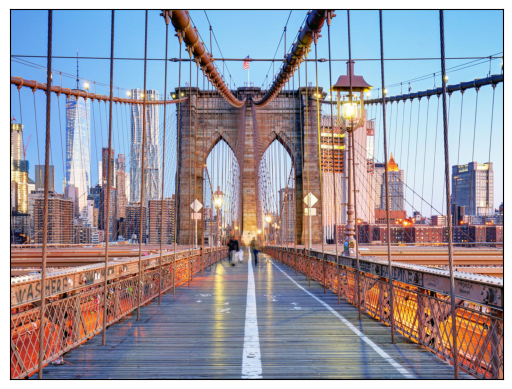

In [ ]:
plt.imshow(img)
plt.xticks([])
plt.yticks([])
plt.show()

In [ ]:
print(img.shape)

(1404, 1872, 3)


In [ ]:
img[:, :, 0]

array([[ 82,  82,  82, ..., 112, 112, 112],
       [ 83,  83,  83, ..., 114, 114, 114],
       [ 84,  84,  84, ..., 116, 116, 116],
       ...,
       [193, 193, 190, ..., 206, 208, 209],
       [180, 192, 202, ..., 205, 206, 207],
       [166, 185, 207, ..., 204, 206, 207]], dtype=uint8)

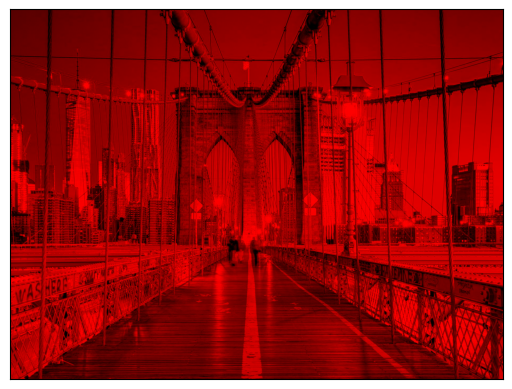

In [ ]:
img_red = img.copy()
img_red[:, :, 1] = np.zeros(img.shape[:2])
# img_red[:, :, 1] = np.zeros((1404, 1872))
img_red[:, :, 2] = np.zeros(img.shape[:2])

plt.imshow(img_red)
plt.xticks([])
plt.yticks([])
plt.show()

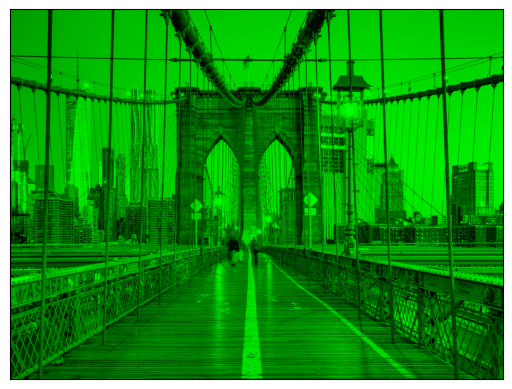

In [ ]:
img_green = img.copy()
img_green[:, :, 0] = np.zeros(img.shape[:2])
img_green[:, :, 2] = np.zeros(img.shape[:2])

plt.imshow(img_green)
plt.xticks([])
plt.yticks([])
plt.show()

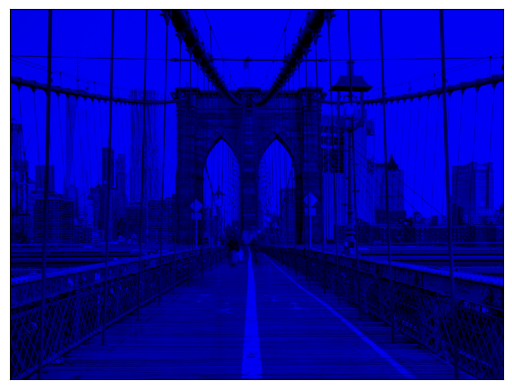

In [ ]:
img_blue = img.copy()
img_blue[:, :, 0] = np.zeros(img.shape[:2])
img_blue[:, :, 1] = np.zeros(img.shape[:2])

plt.imshow(img_blue)
plt.xticks([])
plt.yticks([])
plt.show()

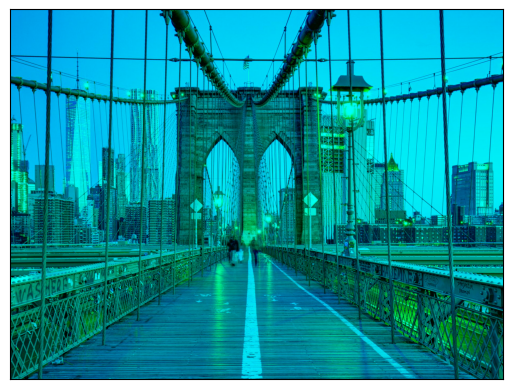

In [ ]:
new_img = img_blue + img_green
plt.imshow(new_img)
plt.xticks([])
plt.yticks([])
plt.show()

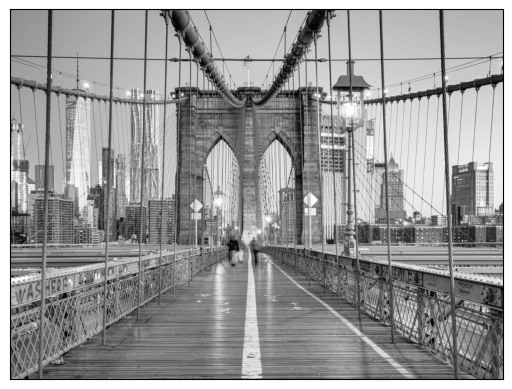

In [ ]:
# Grayscale = (Red * 0.299) + (Green * 0.587) + (Blue * 0.114)

img_grayscale = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]

plt.imshow(img_grayscale, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.show()

In [ ]:
import scipy.signal

$\displaystyle n_o = \Big\lfloor\frac{n_i+2p-f}{s} + 1\Big\rfloor$

In [ ]:
print(img_grayscale.shape)

(1404, 1872)


In [ ]:
Fx = np.array(
    [[1, 0, -1],
     [2, 0 , -2],
     [1, 0, -1]]
)

In [ ]:
def get_output_image_size(n, p, f, s):
    return int(np.floor((n + 2*p - f) / s) + 1)

In [ ]:
get_output_image_size(1404, 0, 3, 1)

1402

In [ ]:
get_output_image_size(1872, 0, 3, 1)

1870

In [ ]:
output_image = scipy.signal.correlate2d(img_grayscale, Fx, mode='valid')

In [ ]:
print(output_image.shape)

(1402, 1870)


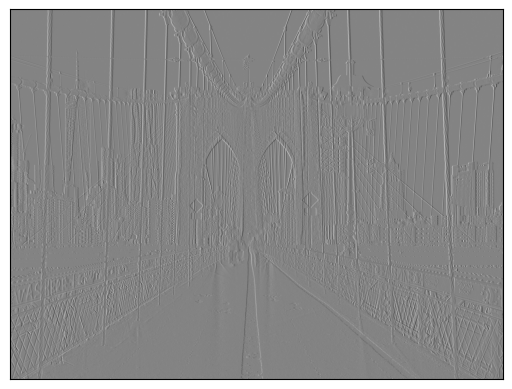

In [ ]:
plt.imshow(output_image, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.show()

(1, 200, 200)
(200, 200)


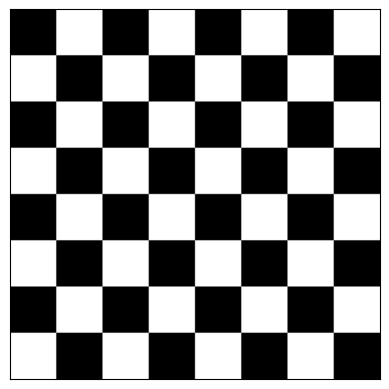

In [ ]:
chess_board = io.imread('https://upload.wikimedia.org/wikipedia/commons/6/67/Chess_board_in_grayscale_in_GIF.gif')
print(chess_board.shape)
chess_board = chess_board[0, :, :]
print(chess_board.shape)
plt.imshow(chess_board, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.show()

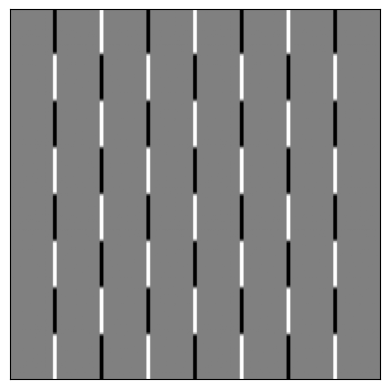

In [ ]:
chess_output = scipy.signal.correlate2d(chess_board, Fx, mode='valid')
plt.imshow(chess_output, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.show()

In [ ]:
Fy = np.array(
    [[1, 2, 1],
     [0, 0 , 0],
     [-1, -2, -1]]
)

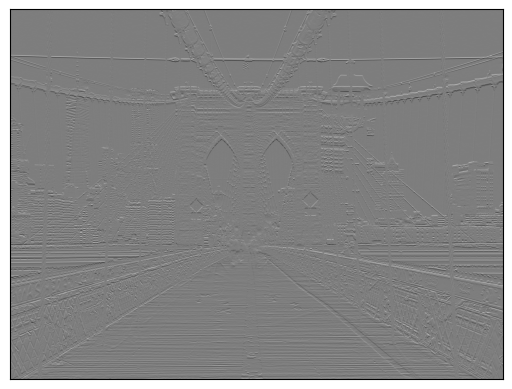

In [ ]:
output_image_2 = scipy.signal.correlate2d(img_grayscale, Fy, mode='valid')
plt.imshow(output_image_2, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.show()

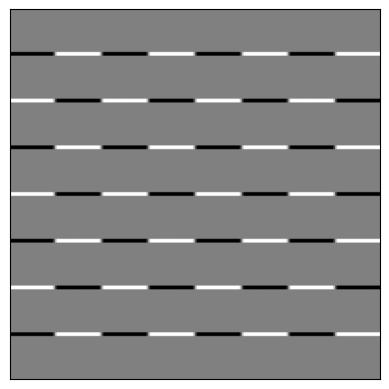

In [ ]:
chess_output_2 = scipy.signal.correlate2d(chess_board, Fy, mode='valid')
plt.imshow(chess_output_2, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.show()

In [ ]:
def gauss_kernel(nx, ny, sig):
    """
    Creates a Gaussian kernel of size (nx,ny) with std deviation sig
    """
    dxsq = (np.arange(nx)-(nx-1)/2)**2
    dysq = (np.arange(ny)-(ny-1)/2)**2
    dsq = dxsq[:,None] + dysq[None,:]
    G = np.exp(-0.5*dsq/(sig**2))
    G = G / np.sum(G)
    return G

In [ ]:
F_gauss = gauss_kernel(9, 9, 3)

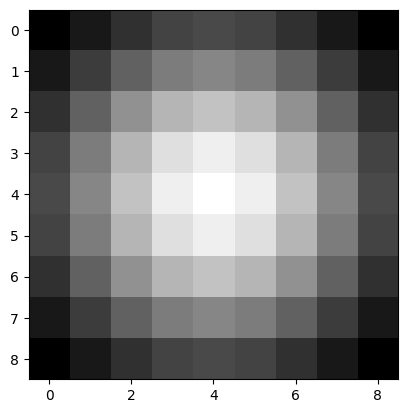

In [ ]:
plt.imshow(F_gauss, cmap='gray')

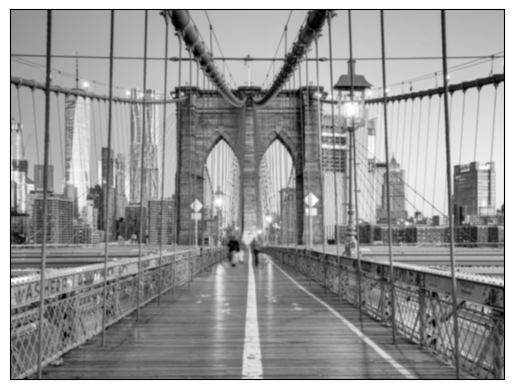

In [ ]:
output_image_3 = scipy.signal.correlate2d(img_grayscale, F_gauss, mode='valid')
plt.imshow(output_image_3, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.show()

Text(0.5, 1.0, 'Gaussian Output')

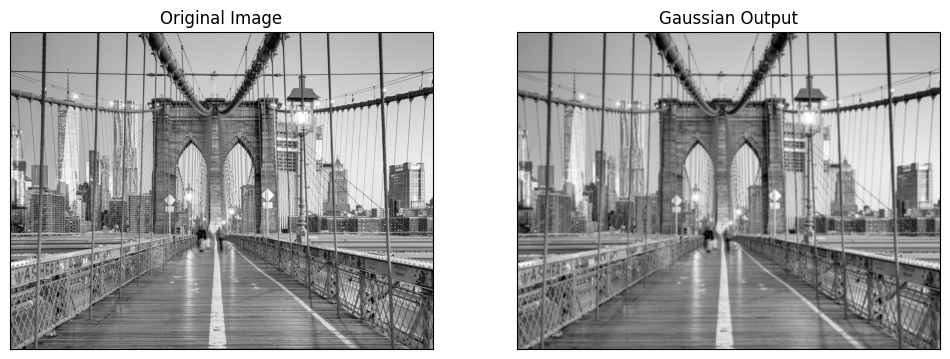

In [ ]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_grayscale, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.title('Original Image')
plt.subplot(1, 2, 2)
plt.imshow(output_image_3, cmap='gray')
plt.xticks([])
plt.yticks([])
plt.title('Gaussian Output')